# 02 · Training an LSTM Beat Classifier

A CNN front-end + bidirectional **LSTM** over each heartbeat waveform, fused with RR-interval rhythm features.

**Validation protocol (inter-patient, no leakage):**

| Set | Records | Used for |
|---|---|---|
| Train | DS1 minus validation patients (17 records) | fitting weights |
| Validation | DS1 patients 106, 118, 124, 201, 205 | early stopping / checkpoint selection on **macro-F1** |
| Test | DS2 (22 records, de Chazal 2004) | final, one-time evaluation; never used for any decision |

No patient appears in more than one set. Model selection uses macro-F1 rather than loss or accuracy:
~90% of beats are normal, so a model that always says "N" already scores ~90% accuracy.

**Classes: N, S, V.** Fusion beats (F) are excluded from training: 373 of the 415 F beats in DS1 belong to one
patient (208), so a model can only memorise that patient. An earlier version that trained on F labelled ~11% of normal
test beats as F. AAMI EC57 likewise does not penalise F beats in ventricular-beat statistics. How the model
classifies F beats is still reported on the test set. Q (paced/unknown) beats are excluded from the inter-patient split.

`SPLIT = "intra_patient"` gives the common (optimistic) random beat split for comparison.

**Output:** `models/ecg_lstm.keras` + `models/ecg_lstm_meta.json`, loaded by the FastAPI app and the LLM tool.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data" / "mitdb"
MODEL_DIR = ROOT / "models"

In [2]:
import json
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras import layers
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.utils.class_weight import compute_class_weight

from app.ecg import mitbih
from app.ecg.evaluation import bootstrap_ci, classification_metrics
from app.ecg.preprocessing import AAMI_CLASSES, BEAT_LEN, RR_FEATURES, TARGET_FS, WINDOW_AFTER, WINDOW_BEFORE

SEED = 42
keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")

In [3]:
# ---- configuration ----
SPLIT = "inter_patient"   # or "intra_patient"
VAL_RECORDS = ["106", "118", "124", "201", "205"]   # validation patients (held out from DS1)
EPOCHS = 20
BATCH_SIZE = 512
PATIENCE = 4
CLASSES = ["N", "S", "V"]  # see intro: F and Q are not learnable inter-patient
MODEL_PATH = MODEL_DIR / "ecg_lstm.keras"
META_PATH = MODEL_DIR / "ecg_lstm_meta.json"
MODEL_DIR.mkdir(exist_ok=True)

## Build datasets

In [4]:
mitbih.download(DATA_DIR)

if SPLIT == "inter_patient":
    train_records = [r for r in mitbih.DS1 if r not in VAL_RECORDS]
    train_d = mitbih.build_dataset(DATA_DIR, train_records)
    val_d = mitbih.build_dataset(DATA_DIR, VAL_RECORDS)
    test_d = mitbih.build_dataset(DATA_DIR, mitbih.DS2)
    assert not set(train_records) & set(VAL_RECORDS) and not set(mitbih.DS1) & set(mitbih.DS2), "patient leakage"
else:
    full = mitbih.build_dataset(DATA_DIR, mitbih.ALL_RECORDS)
    idx = np.arange(len(full["labels"]))
    idx_tmp, idx_te = train_test_split(idx, test_size=0.2, stratify=full["labels"], random_state=SEED)
    idx_tr, idx_va = train_test_split(idx_tmp, test_size=0.15, stratify=full["labels"][idx_tmp], random_state=SEED)
    train_d, val_d, test_d = ({k: v[i] for k, v in full.items()} for i in (idx_tr, idx_va, idx_te))

print("All labels in training patients:", pd.Series(train_d["labels"]).value_counts().to_dict())

def to_xy(d):
    keep = np.isin(d["labels"], CLASSES)
    y = np.array([CLASSES.index(c) for c in d["labels"][keep]])
    return d["beats"][keep][..., None], d["rr"][keep], y, d["record"][keep]

Xb_tr, Xr_tr, y_tr, g_tr = to_xy(train_d)
Xb_va, Xr_va, y_va, g_va = to_xy(val_d)
Xb_te, Xr_te, y_te, g_te = to_xy(test_d)

pd.DataFrame(
    {name: np.bincount(y, minlength=len(CLASSES)) for name, y in [("train", y_tr), ("val", y_va), ("test", y_te)]},
    index=CLASSES,
).assign(**{"patients (train/val/test)": f"{len(set(g_tr))}/{len(set(g_va))}/{len(set(g_te))}"})

All labels in training patients: {'N': 36436, 'V': 2936, 'S': 686, 'F': 396, 'Q': 8}


,train,val,test,patients (train/val/test)
N,36436,9412,44240,17/5/22
S,686,258,1837,17/5/22
V,2936,852,3220,17/5/22


In [5]:
class_weight = {k: float(v) for k, v in enumerate(compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_tr))}
pd.DataFrame({"class": CLASSES, "train_beats": np.bincount(y_tr, minlength=len(CLASSES)), "weight": list(class_weight.values())})

,class,train_beats,weight
0,N,36436,0.366469
1,S,686,19.464529
2,V,2936,4.547911


## Model: Conv1D → BiLSTM ⊕ RR features

In [6]:
def build_model(n_classes: int) -> keras.Model:
    beat_in = keras.Input(shape=(BEAT_LEN, 1), name="beat")
    rr_in = keras.Input(shape=(len(RR_FEATURES),), name="rr")

    x = layers.GaussianNoise(0.1)(beat_in)            # augmentation, active only during training
    x = layers.Conv1D(32, 7, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)                     # 256 -> 64 time steps
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(16))(x)

    r = layers.GaussianNoise(0.03)(rr_in)
    r = layers.Dense(16, activation="relu")(layers.BatchNormalization()(r))

    h = layers.Concatenate()([x, r])
    h = layers.Dense(64, activation="relu")(h)
    h = layers.Dropout(0.4)(h)
    out = layers.Dense(n_classes, activation="softmax", name="beat_class")(h)

    model = keras.Model([beat_in, rr_in], out, name="ecg_lstm")
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_model(len(CLASSES))
model.summary()

Model: "ecg_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ beat (InputLayer)   │ (None, 256, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise      │ (None, 256, 1)    │          0 │ beat[0][0]        │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 256, 32)   │        256 │ gaussian_noise[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 128, 32)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 128, 64)   │     10,304 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 64, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rr (InputLayer)     │ (None, 4)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64, 64)    │     24,832 │ max_pooling1d_1[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise_1    │ (None, 4)         │          0 │ rr[0][0]          │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 64)    │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4)         │         16 │ gaussian_noise_1… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 32)        │     10,368 │ dropout[0][0]     │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │         80 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 48)        │          0 │ bidirectional_1[… │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      3,136 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ beat_class (Dense)  │ (None, 3)         │        195 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 49,571 (193.64 KB)

 Trainable params: 49,371 (192.86 KB)

 Non-trainable params: 200 (800.00 B)

## Train
`ValMacroF1` runs first in the callback list so early stopping, LR scheduling and checkpointing all see `val_macro_f1`.

In [7]:
class ValMacroF1(keras.callbacks.Callback):
    def __init__(self, x, y):
        super().__init__()
        self.x, self.y = x, y

    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.x, batch_size=2048, verbose=0).argmax(1)
        logs["val_macro_f1"] = f1_score(self.y, pred, average="macro", labels=range(len(CLASSES)), zero_division=0)
        logs["val_balanced_acc"] = balanced_accuracy_score(self.y, pred)
        print(f"  epoch {epoch + 1}: val_macro_f1={logs['val_macro_f1']:.4f} val_balanced_acc={logs['val_balanced_acc']:.4f}")

callbacks = [
    ValMacroF1([Xb_va, Xr_va], y_va),
    keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_macro_f1", mode="max", factor=0.5, patience=2, min_lr=1e-5),
    keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_macro_f1", mode="max", save_best_only=True),
    keras.callbacks.CSVLogger(MODEL_DIR / "training_log.csv"),
]
history = model.fit(
    [Xb_tr, Xr_tr], y_tr,
    validation_data=([Xb_va, Xr_va], y_va),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=2,
)
best_epoch = int(np.argmax(history.history["val_macro_f1"])) + 1
print(f"best epoch {best_epoch} · val macro-F1 {max(history.history['val_macro_f1']):.4f}")

Epoch 1/20


  epoch 1: val_macro_f1=0.3372 val_balanced_acc=0.3447
79/79 - 59s - 746ms/step - accuracy: 0.8282 - loss: 0.5809 - val_accuracy: 0.8973 - val_loss: 0.2705 - val_macro_f1: 0.3372 - val_balanced_acc: 0.3447 - learning_rate: 0.0010


Epoch 2/20


  epoch 2: val_macro_f1=0.5054 val_balanced_acc=0.4649
79/79 - 66s - 831ms/step - accuracy: 0.9458 - loss: 0.2009 - val_accuracy: 0.9236 - val_loss: 0.2417 - val_macro_f1: 0.5054 - val_balanced_acc: 0.4649 - learning_rate: 0.0010


Epoch 3/20


  epoch 3: val_macro_f1=0.6686 val_balanced_acc=0.6504
79/79 - 60s - 761ms/step - accuracy: 0.9563 - loss: 0.1595 - val_accuracy: 0.9571 - val_loss: 0.1773 - val_macro_f1: 0.6686 - val_balanced_acc: 0.6504 - learning_rate: 0.0010


... (7 outputs left out)

  epoch 7: val_macro_f1=0.6781 val_balanced_acc=0.6991
79/79 - 58s - 738ms/step - accuracy: 0.9678 - loss: 0.0901 - val_accuracy: 0.9545 - val_loss: 0.1578 - val_macro_f1: 0.6781 - val_balanced_acc: 0.6991 - learning_rate: 5.0000e-04


Epoch 8/20


  epoch 8: val_macro_f1=0.6778 val_balanced_acc=0.6953
79/79 - 58s - 736ms/step - accuracy: 0.9696 - loss: 0.0829 - val_accuracy: 0.9596 - val_loss: 0.1463 - val_macro_f1: 0.6778 - val_balanced_acc: 0.6953 - learning_rate: 5.0000e-04


best epoch 4 · val macro-F1 0.6791


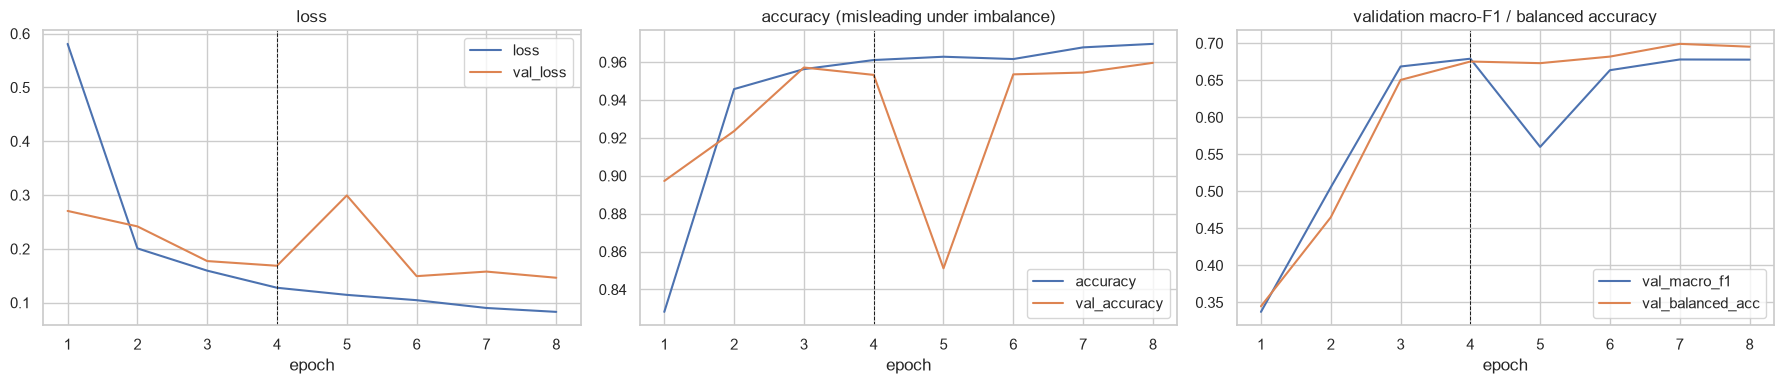

In [8]:
hist = pd.DataFrame(history.history)
hist.index += 1
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
hist[["loss", "val_loss"]].plot(ax=axes[0], title="loss")
hist[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="accuracy (misleading under imbalance)")
hist[["val_macro_f1", "val_balanced_acc"]].plot(ax=axes[2], title="validation macro-F1 / balanced accuracy")
for ax in axes:
    ax.axvline(best_epoch, ls="--", c="k", lw=0.7); ax.set_xlabel("epoch")
plt.tight_layout()

## Validation-set results (used for model selection)

In [9]:
val_metrics = classification_metrics(y_va, model.predict([Xb_va, Xr_va], batch_size=2048, verbose=0).argmax(1), CLASSES)
pd.DataFrame(val_metrics["per_class"]).T

,support,sensitivity,ppv,specificity,f1
N,9412.0,0.9830,0.9795,0.8252,0.9812
S,258.0,0.1860,0.2133,0.9828,0.1988
V,852.0,0.8568,0.8578,0.9875,0.8573


## Baselines (trained on the same training patients)

A model is only useful if it beats simple alternatives:
- **Majority class:** always predict N.
- **RR-only logistic regression:** rhythm features alone, no waveform. This shows how much the LSTM gains from morphology.

In [10]:
rr_baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
rr_baseline.fit(Xr_tr, y_tr)

def summary(name, pred):
    m = classification_metrics(y_te, pred, CLASSES)
    return {"model": name, "accuracy": m["accuracy"], "macro_f1": m["macro_f1"], "balanced_accuracy": m["balanced_accuracy"],
            **{f"Se_{c}": m["per_class"][c]["sensitivity"] for c in CLASSES}, **{f"PPV_{c}": m["per_class"][c]["ppv"] for c in CLASSES}}

pred_te = model.predict([Xb_te, Xr_te], batch_size=2048, verbose=0).argmax(1)
comparison = pd.DataFrame([
    summary("majority (always N)", np.zeros_like(y_te)),
    summary("RR-only logistic regression", rr_baseline.predict(Xr_te)),
    summary("Conv-BiLSTM (this model)", pred_te),
]).set_index("model")
comparison.round(3)

,accuracy,macro_f1,balanced_accuracy,Se_N,Se_S,Se_V,PPV_N,PPV_S,PPV_V
model,,,,,,,,,
majority (always N),0.897,0.315,0.333,1.000,0.000,0.000,0.897,0.000,0.000
RR-only logistic regression,0.872,0.530,0.607,0.908,0.066,0.848,0.986,0.048,0.450
Conv-BiLSTM (this model),0.945,0.650,0.630,0.991,0.096,0.802,0.958,0.361,0.847


## Final evaluation on held-out test patients (DS2)

95% confidence intervals come from a **patient-level bootstrap** (resampling records). Beats from one patient are
correlated, so a beat-level bootstrap would understate the uncertainty.

In [11]:
test_metrics = classification_metrics(y_te, pred_te, CLASSES)
record_cms = [confusion_matrix(y_te[g_te == r], pred_te[g_te == r], labels=range(len(CLASSES))) for r in np.unique(g_te)]
test_ci = bootstrap_ci(record_cms, CLASSES)

print(f"accuracy {test_metrics['accuracy']:.3f} {test_ci['accuracy']} · "
      f"macro-F1 {test_metrics['macro_f1']:.3f} {test_ci['macro_f1']} · "
      f"balanced acc {test_metrics['balanced_accuracy']:.3f} {test_ci['balanced_accuracy']}")
pd.DataFrame({
    c: {**test_metrics["per_class"][c], "Se 95% CI": test_ci["per_class"][c]["sensitivity"], "PPV 95% CI": test_ci["per_class"][c]["ppv"]}
    for c in CLASSES
}).T

accuracy 0.945 [0.8814, 0.9813] · macro-F1 0.650 [0.5443, 0.7771] · balanced acc 0.630 [0.5596, 0.7789]


,support,sensitivity,ppv,specificity,f1,Se 95% CI,PPV 95% CI
N,44240,0.991,0.9581,0.6207,0.9743,"[0.9835, 0.9973]","[0.9038, 0.9901]"
S,1837,0.0958,0.3614,0.9934,0.1515,"[0.0057, 0.4981]","[0.0692, 0.5136]"
V,3220,0.8022,0.8472,0.9899,0.8241,"[0.6037, 0.9256]","[0.543, 0.9696]"


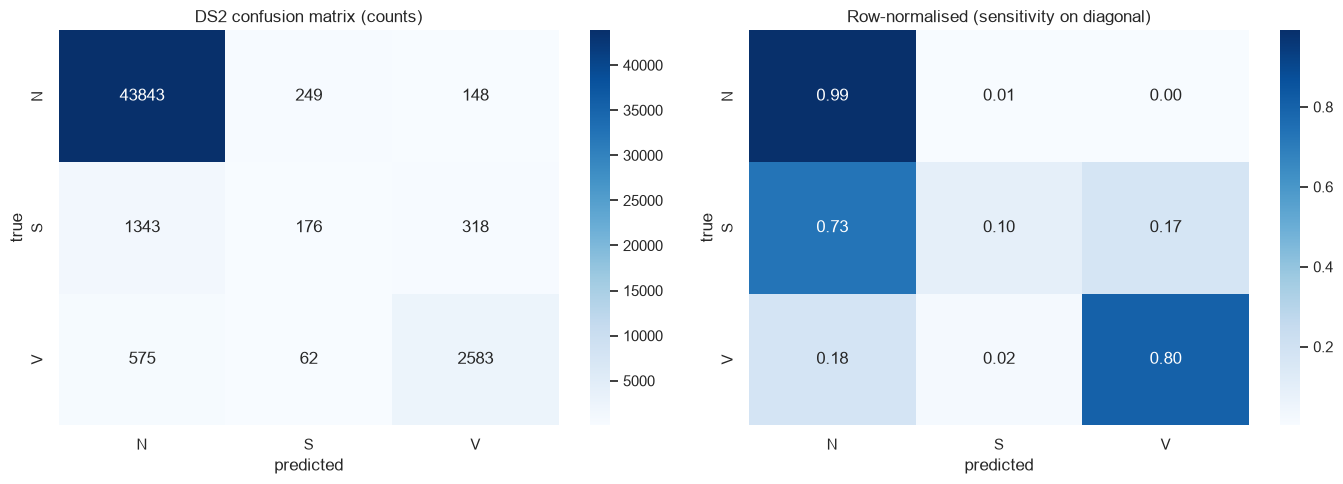

In [12]:
cm = np.array(test_metrics["confusion_matrix"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set(title="DS2 confusion matrix (counts)", xlabel="predicted", ylabel="true")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set(title="Row-normalised (sensitivity on diagonal)", xlabel="predicted", ylabel="true")
plt.tight_layout()

In [13]:
per_rec = pd.DataFrame([
    {"record": r, "beats": int((g_te == r).sum()), "accuracy": float((pred_te[g_te == r] == y_te[g_te == r]).mean()),
     **{f"true_{c}": int((y_te[g_te == r] == i).sum()) for i, c in enumerate(CLASSES)},
     **{f"pred_{c}": int((pred_te[g_te == r] == i).sum()) for i, c in enumerate(CLASSES)}}
    for r in np.unique(g_te)
]).set_index("record")
per_rec.sort_values("accuracy").round(3)

,beats,accuracy,true_N,true_S,true_V,pred_N,pred_S,pred_V
record,,,,,,,,
232,1780,0.222,398,1382,0,1498,2,280
228,2053,0.892,1688,3,362,1885,9,159
222,2481,0.912,2272,209,0,2211,221,49
200,2598,0.929,1742,30,826,1918,9,671
202,2134,0.941,2060,55,19,1978,128,28
213,2888,0.949,2640,28,220,2780,0,108
105,2567,0.962,2526,0,41,2469,29,69
210,2638,0.972,2421,22,195,2473,6,159
214,2257,0.976,2001,0,256,2030,17,210


### How are the excluded fusion (F) beats classified?

In [14]:
f_mask = test_d["labels"] == "F"
f_pred = model.predict([test_d["beats"][f_mask][..., None], test_d["rr"][f_mask]], batch_size=2048, verbose=0).argmax(1)
f_dist = pd.Series([CLASSES[i] for i in f_pred]).value_counts().reindex(CLASSES, fill_value=0)
print(f"{f_mask.sum()} F beats in DS2 predicted as:", f_dist.to_dict())

388 F beats in DS2 predicted as: {'N': 380, 'S': 1, 'V': 7}


## Save model + metadata
The checkpoint already holds the best-validation weights (`restore_best_weights=True` restores them to `model` too).

In [15]:
model.save(MODEL_PATH)
meta = {
    "classes": CLASSES,
    "beat_len": BEAT_LEN,
    "window_before": WINDOW_BEFORE,
    "window_after": WINDOW_AFTER,
    "fs": TARGET_FS,
    "rr_features": RR_FEATURES,
    "split": SPLIT,
    "train_records": sorted(set(g_tr.tolist())),
    "val_records": sorted(set(g_va.tolist())),
    "test_records": sorted(set(g_te.tolist())),
    "best_epoch": best_epoch,
    "epochs_run": len(hist),
    "hyperparameters": {"batch_size": BATCH_SIZE, "max_epochs": EPOCHS, "patience": PATIENCE, "optimizer": "adam", "lr": 1e-3, "seed": SEED},
    "val_metrics": {k: val_metrics[k] for k in ["accuracy", "macro_f1", "balanced_accuracy"]},
    "test_metrics": {k: test_metrics[k] for k in ["accuracy", "macro_f1", "balanced_accuracy", "per_class"]},
    "test_ci95": test_ci,
    "test_fusion_beats_predicted_as": f_dist.to_dict(),
    "baselines_test": comparison[["accuracy", "macro_f1", "balanced_accuracy"]].round(4).to_dict(orient="index"),
}
META_PATH.write_text(json.dumps(meta, indent=2))
print(f"Saved {MODEL_PATH} and {META_PATH}")

Saved /media/sage/HDD/rag_ltsm/ltsm_project/models/ecg_lstm.keras and /media/sage/HDD/rag_ltsm/ltsm_project/models/ecg_lstm_meta.json


## Sanity check: the deployed inference path
Run the same `ECGClassifier` the API uses on a raw, *unseen* strip with **auto-detected** R-peaks, and compare with the annotations.

In [16]:
from app.ecg.classifier import ECGClassifier
from app.ecg.preprocessing import SYMBOL_TO_AAMI

clf = ECGClassifier(MODEL_PATH, META_PATH)
# reloaded model must give identical predictions
np.testing.assert_allclose(clf.predict_beats(Xb_te[:500, :, 0], Xr_te[:500]), model.predict([Xb_te[:500], Xr_te[:500]], verbose=0), atol=1e-5)

sig, samples, symbols, fs = mitbih.load_record(DATA_DIR, "233")   # DS2 record with many PVCs
strip = sig[: 60 * fs]
result = clf.analyze(strip, fs)

in_strip = (samples < len(strip)) & np.isin(symbols, list(SYMBOL_TO_AAMI))
truth = pd.Series([SYMBOL_TO_AAMI[s] for s in symbols[in_strip]]).value_counts().to_dict()
print("Annotated :", truth)
print("Predicted :", result["beat_counts"])
print("HR        :", result["heart_rate_bpm"], "bpm")

print("\nFull DS2 evaluation incl. end-to-end detection: python scripts/evaluate_model.py")

Annotated : {'N': 72, 'V': 30, 'S': 2}
Predicted : {'N': 73, 'S': 0, 'V': 29}
HR        : 103.4 bpm

Full DS2 evaluation incl. end-to-end detection: python scripts/evaluate_model.py
